# PW5 - Linear Regression

Ex1 took me 2 hours, as i discovered skewness, and did heavy work on the scatter plot

Ex2 took me 2 hours as i worked on showing clean outputs of the calculations

## Imports

In [26]:
import random
import pandas as pd
import numpy as np
from numpy.linalg import inv
import matplotlib.pyplot as plt

## Load data

Define the path to the file containing the data

In [27]:
datafile = "lausanne-appart.csv"

Read the data

In [3]:
dataset = pd.read_csv(datafile)

Display first rows

In [4]:
dataset.head()

,living_area,nb_rooms,rent_price
0,69,3.0,1810
1,95,3.5,2945
2,21,1.5,685
3,20,1.0,720
4,33,1.5,830


## Exercise 1 - Visualize the data

a) Plot a histogram to visualize the distribution of the renting price

In [28]:
# Bonus code - Descriptive analysis
rent_price = dataset.rent_price.values

print("="*40)
print("DESCRIPTIVE STATISTICS - RENT PRICES")
print("="*40)

# We use :<15 to align labels to the left and :>10.2f to align numbers to the right
print(f"{'Minimum:':<15} {np.min(rent_price):>10.2f} CHF")
print(f"{'Maximum:':<15} {np.max(rent_price):>10.2f} CHF")
print("-" * 40)
print(f"{'Mean:':<15} {np.mean(rent_price):>10.2f} CHF")
print(f"{'Median:':<15} {np.median(rent_price):>10.2f} CHF")
print(f"{'Skewness:':<15} {dataset.rent_price.skew():>10.4f}")
print("="*40)

DESCRIPTIVE STATISTICS - RENT PRICES
Minimum:            685.00 CHF
Maximum:           7383.00 CHF
----------------------------------------
Mean:              2378.24 CHF
Median:            2145.00 CHF
Skewness:           1.3354


The rent prices show a positive skewness of 1.3354. Since the mean (2378.24 CHF) is higher than the median (2145.00 CHF), the distribution is right-skewed, indicating that a few expensive apartments are pulling the average upwards.

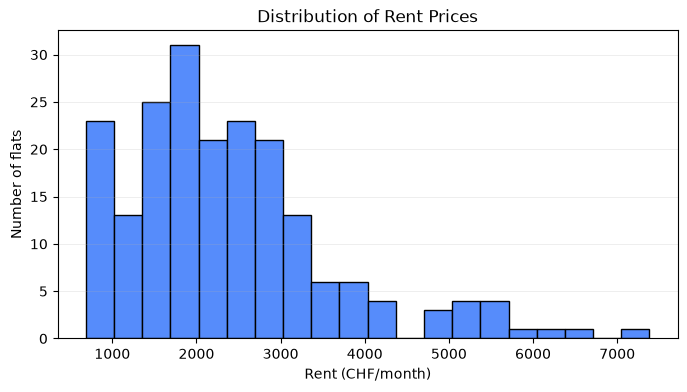

In [29]:
# Your code here
plt.figure(figsize=(8, 4))
plt.hist(rent_price, bins=20, edgecolor='black')
plt.xlabel("Rent (CHF/month)")
plt.ylabel("Number of flats")
plt.title("Distribution of Rent Prices")
plt.grid(axis='y', alpha=0.3)
plt.show()



From this histogram, we can see that the rental market distribution is unimodal and characterized by a high concentration of affordable housing between 1,500 and 2,500 CHF. However, the market is heavily influenced by a luxury segment (outliers), which creates a long right tail and shifts the average rent higher than the typical (median) rent.

b) Plot a histogram to visualize the distribution of the living area

In [30]:
# Bonus code - Descriptive analysis
living_area = dataset.living_area.values

print("="*40)
print("DESCRIPTIVE STATISTICS - LIVING AREAS")
print("="*40)

# We use :<15 to align labels to the left and :>10.2f to align numbers to the right
print(f"{'Minimum:':<15} {np.min(living_area):>10.2f} m^2")
print(f"{'Maximum:':<15} {np.max(living_area):>10.2f} m^2")
print("-" * 40)
print(f"{'Mean:':<15} {np.mean(living_area):>10.2f} m^2")
print(f"{'Median:':<15} {np.median(living_area):>10.2f} m^2")
print(f"{'Skewness:':<15} {dataset.living_area.skew():>10.4f}")
print("="*40)

DESCRIPTIVE STATISTICS - LIVING AREAS
Minimum:             13.00 m^2
Maximum:            240.00 m^2
----------------------------------------
Mean:                81.20 m^2
Median:              80.00 m^2
Skewness:           0.7413


The distribution of living areas exhibits a positive skewness of 0.7413. Since the mean (81.20 $m^2$) is higher than the median (80.00 $m^2$), the distribution is right-skewed. This indicates that the presence of larger apartments (up to 240 $m^2$) is pulling the average upwards, away from the median. The distribution of the living area mirrors the distribution of rent prices, suggesting that the premium prices in the dataset are driven by the larger properties (outliers in area).

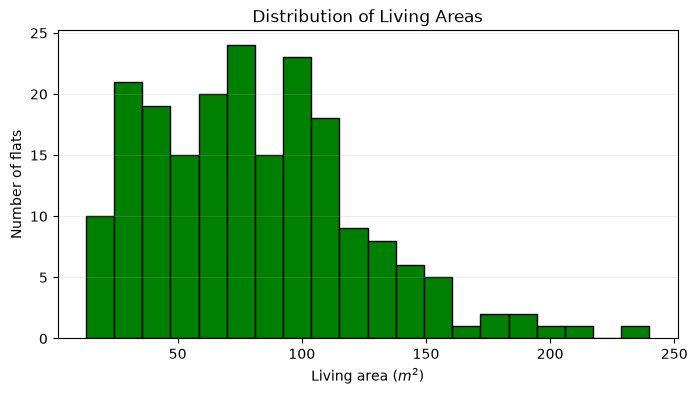

In [31]:
# Your code here
plt.figure(figsize=(8, 4))
plt.hist(living_area, bins=20, color='green', edgecolor='black')
plt.xlabel("Living area ($m^2$)")
plt.ylabel("Number of flats")
plt.title("Distribution of Living Areas")
plt.title("Distribution of Living Areas")
plt.grid(axis='y', alpha=0.3)
plt.show()


From this histogram, we can see that the living area distribution is unimodal and characterized by a high concentration of properties between 30 and 100 $m^2$. However, the distribution is heavily influenced by large-sized properties (outliers), which creates a long right tail and shifts the average area higher than the median.

c) Plot a scatter plot of renting price as a function of living area

In [9]:
# bonus code
correlation = dataset['living_area'].corr(dataset['rent_price'])
print(f"Correlation coefficient: {correlation:.4f}")

Correlation coefficient: 0.9042


We observe a strong positive correlation of 0.9 between living area and rent price, confirming the intuitive relationship.

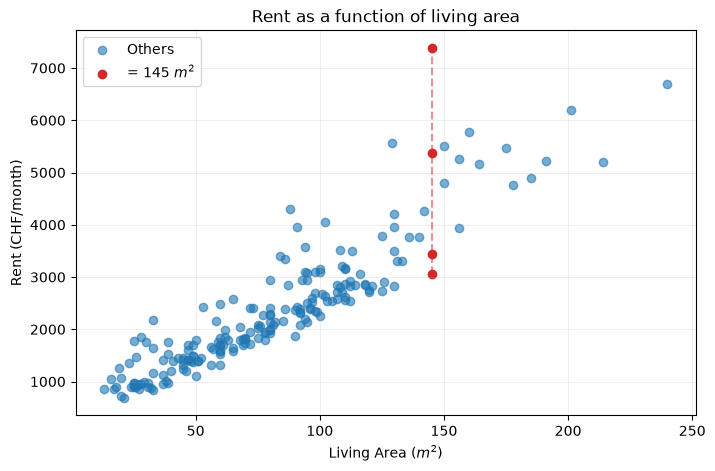

In [25]:
# Your code here

# Convert to numpy arrays so we can do element-wise maths and filter with masks
living_area = np.asarray(living_area)
rent_price = np.asarray(rent_price)

# Boolean masks, True where the point belongs to that group
is_145 = living_area == 145 # exactly 145 m^2
is_other = ~is_145  # all the rest

plt.figure(3, figsize=(8, 5))
plt.scatter(living_area[is_other], rent_price[is_other], color="tab:blue", alpha=0.6, label="Others")
plt.scatter(living_area[is_145], rent_price[is_145], color="tab:red", label="= 145 $m^2$")

# Dashed vertical lines showing the price gap between flats of 145m^2
plt.vlines(145, rent_price[is_145].min(), rent_price[is_145].max(), color="tab:red", linestyle="--", alpha=0.5)

plt.xlabel("Living Area ($m^2$)")
plt.ylabel("Rent (CHF/month)")
plt.title("Rent as a function of living area")
plt.grid(axis='both', alpha=0.3)
plt.legend()
plt.show()

From this scatter plot, we can see that the distribution shows heteroscedasticity. The error variance appears to increase as the living area and rent increase. We can see for example a significant variance at the 145 $m^2$ mark. Despite not being the maximum surface area, the 145 $m^2$ group includes high-value outliers (reaching over 7,000 CHF!). This price discrepancy suggests that other latent variables significantly influence the rental price, making the relationship non-trivial.

## Exercise 2 - Normal equations for linear regression

a) Implement the closed form solution to this problem using the following normal equation:

<div><div style="display: table-cell; width: 100%;"><center>$\theta = (X^{T}X)^{-1}X^{T}\vec{y}$</center></div><div style="display: table-cell; width: 100%;">$(3)$</div></div>

Assuming $x$ is the living area and $y$ is the renting price. Use `numpy` for the vector operations. Plot the computed line on top of the scatter plot of exercise 1.

---------------------------------------------
           NORMAL EQUATION RESULTS
---------------------------------------------
Dataset size (N) : 201
X shape          : (201, 2)
y shape          : (201,)
---------------------------------------------
theta_0 (intercept) : 240.08 CHF
theta_1 (slope)     : 26.33 CHF/m2
Model equation      : Rent = 240.08 + 26.33 * Area
---------------------------------------------


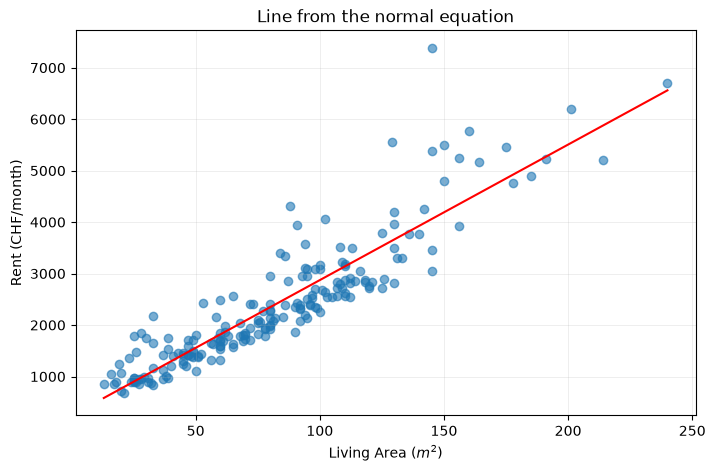

In [70]:
# Your code here
N = len(living_area)
X = np.ones((N, 2)) # 201 rows of [1., 1.]
X[:, 1] = living_area # column 1 gets the living areas
y = rent_price

XtX = X.T.dot(X)
Xty = X.T.dot(y)
XtX_inv = inv(XtX)

theta = XtX_inv.dot(Xty)

## Clean output
print("-" * 45)
print(" "*11 + "NORMAL EQUATION RESULTS")
print("-" * 45)
print(f"Dataset size (N) : {N}")
print(f"X shape          : {X.shape}")
print(f"y shape          : {y.shape}")
print("-" * 45)
print(f"theta_0 (intercept) : {theta[0]:.2f} CHF")
print(f"theta_1 (slope)     : {theta[1]:.2f} CHF/m2")
print(f"Model equation      : Rent = {theta[0]:.2f} + {theta[1]:.2f} * Area")
print("-" * 45)

## Regression plot
x_line = np.linspace(np.min(living_area), np.max(living_area))
y_line = theta[0] + theta[1] * x_line

plt.figure(4, figsize=(8, 5))
plt.scatter(living_area, rent_price, color="tab:blue", alpha=0.6)
plt.plot(x_line, y_line, color="red")
plt.xlabel("Living Area ($m^2$)")
plt.ylabel("Rent (CHF/month)")
plt.title("Line from the normal equation")
plt.grid(axis='both', alpha=0.3)
plt.show()


b) Compute the overall cost value according to the following equation:

<div><div style="display: table-cell; width: 100%;"><center>$J(\theta) = \frac{1}{2N} \sum_{n=1}^{N} (h_{\theta}(\mathbf{x}_{n}) - y_{n})^{2}$</center></div><div style="display: table-cell; width: 100%;">$(2)$</div></div>

In [87]:
# Your code here

## Compute predictions and cost
y_hat = X.dot(theta)
residuals = y_hat - y
sum_of_squared_erros = np.sum(residuals ** 2)
J = sum_of_squared_erros / (2 * N)

## Show first 3 samples result as preview
df_preview = pd.DataFrame(
    {
        "Area (m2)": living_area[:3],
        "y (True)": y[:3],
        "y_hat": y_hat[:3].round(2),
        "Error": residuals[:3].round(2),
        "Sq Error": (residuals[:3] ** 2).round(2),
    }
)
width = 50

print("-" * width)
print("SAMPLE PREDICTIONS (FIRST 3 ROWS)".center(width))
print("-" * width)
print(df_preview.to_string(index=False))
print("-" * width)

## Show cost function summary
print("\n" + "-" * width)
print("COST FUNCTION EVALUATION : J(theta)".center(width))
print("-" * width)
print(f"Dataset size (N)        : {N}")
print(f"Sum of Squared Errors   : {sum_of_squared_erros:.2f}")
print(f"Cost value J(theta)     : {J:.2f}")
print("-" * width)



--------------------------------------------------
        SAMPLE PREDICTIONS (FIRST 3 ROWS)         
--------------------------------------------------
 Area (m2)  y (True)   y_hat   Error  Sq Error
        69      1810 2057.01  247.01  61016.12
        95      2945 2741.66 -203.34  41348.20
        21       685  793.06  108.06  11676.54
--------------------------------------------------

--------------------------------------------------
       COST FUNCTION EVALUATION : J(theta)        
--------------------------------------------------
Dataset size (N)        : 201
Sum of Squared Errors   : 55490053.03
Cost value J(theta)     : 138034.96
--------------------------------------------------


c) The cost value reflects the performance of your system. Is this cost value *readable* for a client of your system ? What other metric could we use to make it more readable to the client ? Optional: implement it.

No, the cost value $J(\theta)$ is not readable for a client. The residuals are squared, $J(\theta)$ is expressed in squared Swiss Francs ($\text{CHF}^2$) and this unit has no real sense as a financial interpretation for a client.

But fortunately there are easy ways to show results that will talk to a client, here is the three alternative metrics we can use:

**RMSE (Root Mean Squared Error)**
$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{n=1}^{N} (y_n - \hat{y}_n)^2}$$

The RMSE restores the error unit to CHF while penalizing large outliers more severely than MAE due to the squaring step.

**MAE (Mean Absolute Error)**
$$\text{MAE} = \frac{1}{N} \sum_{n=1}^{N} \vert{}y_n - \hat{y}_n\vert{}$$

The MAE measures the average magnitude of errors in raw CHF. A client then can understand *"on average, predictions are off by X francs."*

**MAPE (Mean Absolute Percentage Error)**
$$\text{MAPE} = \frac{1}{N} \sum_{n=1}^{N} \left\vert{}\frac{y_n - \hat{y}_n}{y_n}\right\vert{} \times 100\%$$

The MAPE expresses relative inaccuracy as a percentage of the actual rent. *(Limitation: MAPE can become unstable if target values approach zero).*

In [98]:
# bonus code

## Implementation of RMSE
rmse = np.sqrt(np.mean(residuals ** 2))

## Implementation of MAE
mae = np.mean(np.abs(residuals))

## Implementation of MAPE
mape = np.mean(np.abs(residuals) / y) * 100

# Show a clean output
print("-" * width)
print("CLIENT-FRIENDLY PERFORMANCE METRICS".center(width))
print("-" * width)
print(f"Cost Value J(theta) : {J:10.2f} CHF^2 (uninterpretable)")
print("-" * width)
print(f"MAE                 : {mae:10.2f} CHF")
print(f"RMSE                : {rmse:10.2f} CHF")
print(f"MAPE                : {mape:10.2f} %")
print("-" * width)
print(f"Interpretation: On average, the rent is off by {mae:.0f} CHF ({mape:.1f}%).")
print("-" * width)


--------------------------------------------------
       CLIENT-FRIENDLY PERFORMANCE METRICS        
--------------------------------------------------
Cost Value J(theta) :  138034.96 CHF^2 (uninterpretable)
--------------------------------------------------
MAE                 :     368.18 CHF
RMSE                :     525.42 CHF
MAPE                :      15.40 %
--------------------------------------------------
Interpretation: On average, the rent is off by 368 CHF (15.4%).
--------------------------------------------------


## Exercise 3 - Gradient descent for linear regression

Implement the _full batch_ gradient descent algorithm for the previous problem. As seen in the
theory, the update rules are:

<div><div style="display: table-cell; width: 100%;"><center>$\theta_{0} \leftarrow \theta_{0} - \alpha \frac{1}{N} \sum_{n=1}^{N} (h_{\theta}(\mathbf{x}_{n}) - y_{n})$</center></div><div style="display: table-cell; width: 100%;">$(6)$</div></div>

<div><div style="display: table-cell; width: 100%;"><center>$\theta_{1} \leftarrow \theta_{1} - \alpha \frac{1}{N} \sum_{n=1}^{N} (h_{\theta}(\mathbf{x}_{n}) - y_{n}) x_{n,1}$</center></div><div style="display: table-cell; width: 100%;">$(7)$</div></div>

**Remark** You need to iterate several times over the training set. If you have problems of convergence, you need to use a smaller value of $\alpha$. Values such as $0.000001$ are common.

In [10]:
# Your code here

a) Plot the cost value (Equation 2) as a function of the iterations. What do you observe?

In [11]:
# Your code here

_Your answer here_

b) Imagine a stopping criterion, i.e. when do we stop iterating on the training set?

_Your answer here_

c) Plot the computed line $h_{\theta}(\mathbf{x})$ on top of the scatter plot of exercise 1.

In [12]:
# Your code here

d) Compute the final cost value according to Equation 2 and compare it to the one of exercise 2. What can you conclude?

In [13]:
# Your code here

_Your answer here_

## Exercise 4 - Stochastic gradient descent for linear regression

Implement the stochastic gradient descent algorithm for the previous problem. As seen in the theory, the update rules are:

<div><div style="display: table-cell; width: 100%;"><center>$\theta_{i} \leftarrow \theta_{i} - \alpha (h_{\theta}(\mathbf{x}_{n}) - y_{n}) x_{n,i}$</center></div><div style="display: table-cell; width: 100%;">$(8)$</div></div>

In [14]:
# Your code here

a) Plot the computed line $h_{\theta}(\mathbf{x})$ on top of the scatter plot of exercise 1.

In [15]:
# Your code here

b) How many samples do you need to visit for reaching the convergence?

_Your answer here_

c) How to observe the convergence? Propose a strategy to observe the convergence as in Ex 3 a), the problem being that we don’t have anymore a notion of epoch.

_Your answer here_

d) Optional: What kind of stopping criterion could we use here? Propose a strategy.

_Your answer here_

e) Compute the final cost value according to Equation 2 and compare it to the one of exercise 2 and 3. What can you conclude?

In [16]:
# Your code here

_Your answer here_

## Exercise 5 - Review questions

a) The linear regression has a mathematical _closed form_ solution. Then, in which conditions would we prefer a gradient descent algorithm to compute the regression model?

_Your answer here_

b) Outliers in a data set can be defined as values that are out of the "usual" range in comparison with other values. They typically come from noise or anomalies in the data capturing process. What is the impact of an outlier in the stochastic gradient descent process? What if we have many outliers? _Hint_: look at the equation of the MSE, and to the equation of the update rule.

_Your answer here_

c) In the case of stochastic gradient descent, what is the danger of having a too large or too small $\alpha$ value? Could you think of a better (more advanced) strategy as the one stated in Slide 36?

_Your answer here_

d) Let's assume we expect that the target variable $y$ has a dependency to the square and to the cube of one of the feature $x_d$ in our multi-variable training set $(x_1, \ldots, x_d, \ldots, x_D)$. How would you proceed? Do we need to take precautions in terms of numerical stability?

_Your answer here_

e) _Advanced_. Could we use a descent algorithm without computing the gradient? If yes, give a pseudo code of the algorithm to find $(\theta_{0}, \theta_{1})$ using a linear regression $h_{\theta}(x) = \theta_0 + \theta_1 x$.

_Your answer here_

## Exercise 6 - Optional - Mini-batch gradient descent for linear regression

Implement the _mini-batch_ gradient descent algorithm for the previous problem, adding a parameter $B$ defining the size of the mini-batch.

In [ ]:
# Your code here

Check that when $B = N$, you fall back on the batch gradient descent solution, and when $B = 1$, you get the behaviour of stochastic gradient descent.

In [ ]:
# Your code here

_Your answer here_

## Exercise 7 - Optional - Multi-variable linear regression

**Hint** For these two exercises, you may need to perform a normalization of the input data, such as min-max rescaling or z-norm.

a) Implement one of the gradient descent algorithm (ex. 3-5) for the multi-variable linear regression assuming $x_1$ being the living area and $x_2$ the square of the living area. Plot the computed curve (second order) on top of the scatter plot of exercise 1. Do you observe a reduction in the loss?

In [ ]:
# Your code here

_Your answer here_

b) Implement one of the gradient descent algorithm (ex. 3-5) for the multi-variable linear regression assuming $x_1$ being the living area and $x_2$ the number of bedrooms. Do you observe a reduction in the loss?

In [ ]:
# Your code here

_Your answer here_